In [13]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from numpy.polynomial.legendre import legvander

In [14]:
SEED = 42                           # SEED wird dafür gebraucht, dass sich nicht bei jedem Lauf die Anfangsbedingungen, die Trainings-, Validierungsdaten und die Anfänglichen Gewichte des Autoencoders verändern

np.random.seed(SEED)
torch.manual_seed(SEED)

rng = np.random.default_rng(SEED)

# Anzahl der Trajektorien
N_TRAIN_TRAJECTORIES = 200
N_VAL_TRAJECTORIES = 20

# Trainingsparameter
BATCH_SIZE = 1024
EPOCHS = 700                       # Anzahl der Epochen, die trainiert werden. 1 Epoche = Modell hat alle Trainingsdateien gesehen
LEARNING_RATE = 1e-3
PRINT_FREQUENCY = 10

Definition des Lorenzsystems

In [15]:
def lorenz(state, t, sigma=10., rho=28., beta=8/3):

    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]

Räumliche Basis

In [16]:
t = np.arange(0.0, 5.0, 0.02)       # Erzeugen eines Zeitvektors. t = 0.0 bis t = 5.0 Schrittweite = 0.02. Ergibt 250 Zeitpunkte
grid = np.linspace(-1, 1, 128)      # Erzeugt 128 gleichmäßig verteilte Punkte auf dem Intervall [-1, 1]
U = legvander(grid, 5)              # Erzeugt Vandermonde-Matrix für Legendre-Polynome. Für jeden Punkt aus grid werden die ersten 6 Legendre-Polynome ausgewertet.

Erstellen des künstlichen 128 dimensionalen Datensatz

In [17]:
def create_lorenz_dataset(number_of_trajectories):
    ic_means = np.array([0.0, 0.0, 25.0])                                                                       # Mittelpunkte der Verteilung der Anfangszustände
    ic_widths = 2.0 * np.array([36.0, 48.0, 41.0])                                                              # Intervallbreiten
    initial_conditions = (ic_widths * (np.random.rand(number_of_trajectories, 3) - 0.5)) + ic_means             # Erstellen der zufälligen Anfangszustände

    Z_raw = np.stack([odeint(lorenz, z0, t) for z0 in initial_conditions])

    Z_scaled = Z_raw / 40.0                                                                                     # Normalisierung

    Z_scaled = Z_scaled.astype(np.float32)

    modes = np.concatenate([                                                                                    # Erstellen der Gleichung aus dem Paper: z1(t), z2(t), z3(t), z1(t)^3, z2(t)^3, z3(t)^3
        Z_scaled,
        Z_scaled**3
    ], axis=2)

    X = modes @ U.T                                                                                             # modes wird mit transponierter Legendre-Matrix multipliziert


    return Z_raw, Z_scaled, X.astype(np.float32)

Trainings, Validierrungs- und Testdaten erzeugen

In [18]:
# Daten werden nach Trajektorien getrennt
Z_train_raw, Z_train, X_train = create_lorenz_dataset(N_TRAIN_TRAJECTORIES)
Z_val_raw, Z_val, X_val = create_lorenz_dataset(N_VAL_TRAJECTORIES)

# Abflachen der Daten, zusammenfassen Trajektorie- und Zeitachse
X_train_flat = X_train.reshape(-1, 128)
X_val_flat = X_val.reshape(-1, 128)

Z_train_flat = Z_train.reshape(-1, 3)
Z_val_flat = Z_val.reshape(-1, 3)

Umwandeln des Formats, damit PyTorch-Modell damit trainiert werden kann

In [19]:
X_train_tensor = torch.from_numpy(X_train_flat)
X_val_tensor = torch.from_numpy(X_val_flat)

Daten für Training mit PyTorch vorbereiten

In [20]:
train_dataset = TensorDataset(X_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

Erstellen des Autoencoders

In [21]:
class LorenzAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(128, 64),
            nn.SiLU(),

            nn.Linear(64, 32),
            nn.SiLU(),

            nn.Linear(32, 16),
            nn.SiLU(),

            nn.Linear(16, 3),
        )

        self.decoder = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),

            nn.Linear(16, 32),
            nn.SiLU(),

            nn.Linear(32, 64),
            nn.SiLU(),

            nn.Linear(64, 128),

        )

    def forward(self, x):

        z = self.encoder(x)
        x_hat = self.decoder(z)

        return x_hat, z

Trainieren des Autoencoders

In [22]:
model = LorenzAutoencoder()
criterion = nn.MSELoss()                                    # Mean Squared Error Fehlerfunktion

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

train_loss_history = []
val_loss_history = []


for epoch in range(EPOCHS):

    # Training des Modells
    model.train()
    total_squared_error = 0
    total_elements = 0

    for (x_batch,) in train_loader:

        optimizer.zero_grad()
        x_hat, z_latent = model(x_batch)                           # x_batch -> Encoder -> z_latent -> Decoder -> x_hat
        loss = criterion(x_hat, x_batch)                           # Autoencoder wird bestraft, wenn x_hat vom Original x_batch abweicht
        loss.backward()                                            # Berechnen des Gradienten.
        optimizer.step()                                           # Gewichte des Modells werden aktualisiert
        total_squared_error += (loss.item() * x_batch.numel())
        total_elements += x_batch.numel()

    train_loss = total_squared_error / total_elements
    train_loss_history.append(train_loss)

    # Validierung des Modells
    model.eval()
    with torch.inference_mode():
        X_val_hat, _ = model(X_val_tensor)
        val_loss = criterion(X_val_hat, X_val_tensor).item()

    val_loss_history.append(val_loss)

    if epoch % PRINT_FREQUENCY == 0 or epoch == EPOCHS - 1:
        print(
           f"Epoch {epoch:4d} | "
            f"Training loss: {train_loss:.6e} | "
            f"Validation loss: {val_loss:.6e}"
        )

Epoch    0 | Training loss: 1.424686e-01 | Validation loss: 6.101881e-02
Epoch   10 | Training loss: 3.175113e-03 | Validation loss: 2.260296e-03
Epoch   20 | Training loss: 2.616330e-04 | Validation loss: 2.771906e-04
Epoch   30 | Training loss: 9.934251e-05 | Validation loss: 8.056481e-05
Epoch   40 | Training loss: 6.461725e-05 | Validation loss: 4.962715e-05
Epoch   50 | Training loss: 4.725034e-05 | Validation loss: 3.046766e-05
Epoch   60 | Training loss: 3.498356e-05 | Validation loss: 2.469379e-05
Epoch   70 | Training loss: 2.651493e-05 | Validation loss: 1.969988e-05
Epoch   80 | Training loss: 2.308363e-05 | Validation loss: 1.867020e-05
Epoch   90 | Training loss: 2.290159e-05 | Validation loss: 1.018342e-05
Epoch  100 | Training loss: 3.788552e-05 | Validation loss: 1.320052e-05
Epoch  110 | Training loss: 2.129324e-05 | Validation loss: 2.095461e-05
Epoch  120 | Training loss: 1.965448e-05 | Validation loss: 1.041139e-05
Epoch  130 | Training loss: 1.060018e-05 | Validati

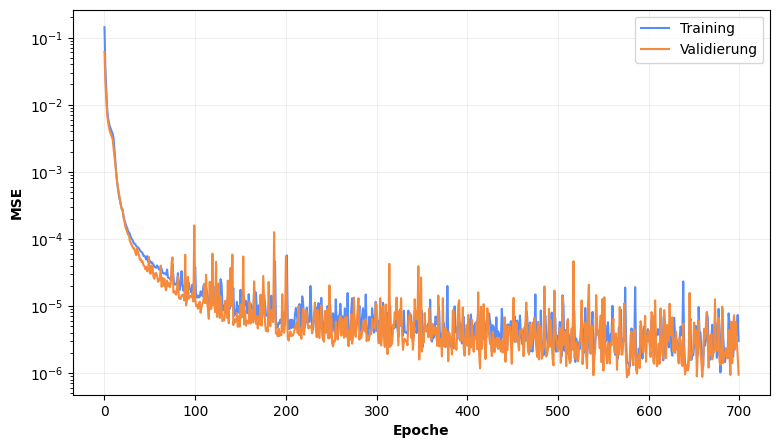

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    train_loss_history,
    label="Training"
)

plt.plot(
    val_loss_history,
    label="Validierung"
)

plt.yscale("log")
plt.xlabel("Epoche", fontweight='bold')
plt.ylabel("MSE", fontweight='bold')

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("TrainingsGraph_SiLU.pdf", dpi=200)

plt.show()

Darstellen der Rekonstruktion

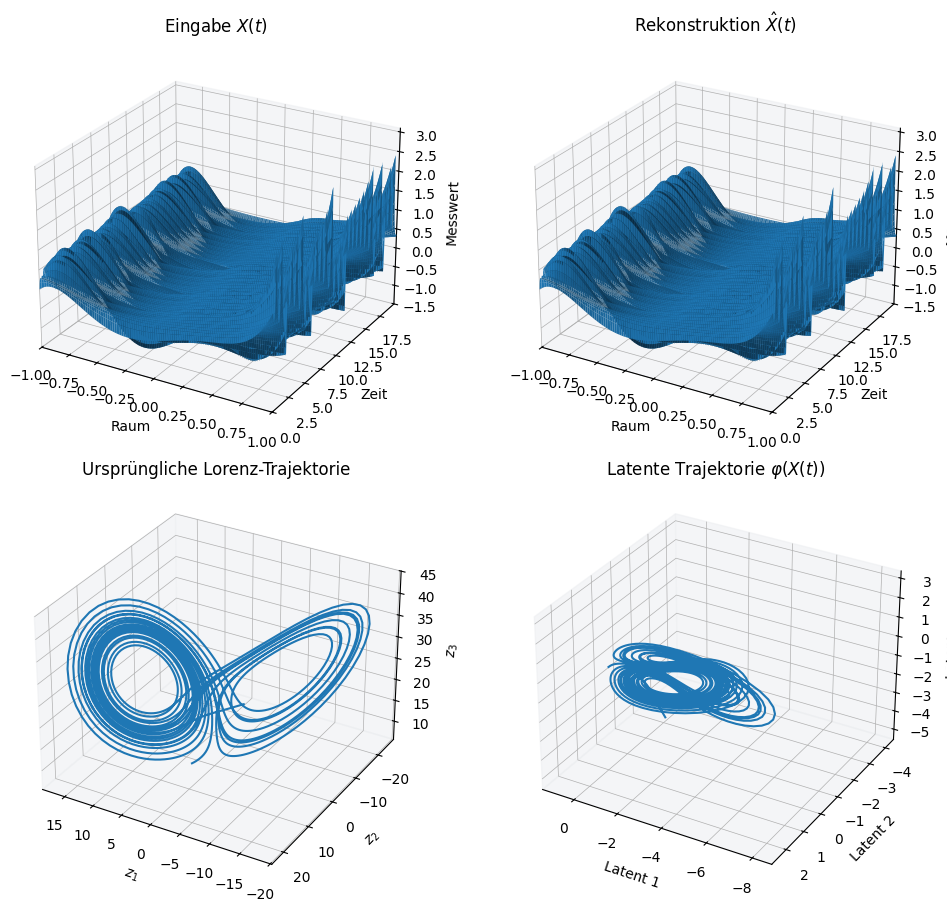

In [24]:
t_plot = np.arange(0.0, 20.0, 0.01)
z0_plot = np.array([-8.0, 7.0, 27.0])

# Lorenz-System simulieren und wie beim Training skalieren
Z_plot_raw = odeint(lorenz, z0_plot, t_plot)

# Skalierte Zustände für die Konstruktion der 128D-Beobachtungen
Z_plot = (Z_plot_raw / 40.0).astype(np.float32)

# Die gleiche 128D-Abbildung wie beim Training
modes_plot = np.concatenate(
    [Z_plot, Z_plot**3],
    axis=1
)

X_plot = (modes_plot @ U.T).astype(np.float32)

X_plot_tensor = torch.from_numpy(X_plot)

model.eval()

with torch.inference_mode():
    X_reconstructed_tensor, Z_encoded_tensor = model(X_plot_tensor)

X_reconstructed = X_reconstructed_tensor.numpy()
Z_encoded = Z_encoded_tensor.numpy()


SPACE, TIME = np.meshgrid(grid, t_plot)


value_min = min(X_plot.min(), X_reconstructed.min())
value_max = max(X_plot.max(), X_reconstructed.max())

padding = 0.05 * max(value_max - value_min, 1e-6)

fig = plt.figure(figsize=(10, 9), layout="constrained")

# Zwei Zeilen und vier Spalten als Anordnungsraster
gs = fig.add_gridspec(2, 4)

# Oben: Eingabe und Rekonstruktion nebeneinander
ax_input = fig.add_subplot(gs[0, 0:2], projection="3d")
ax_output = fig.add_subplot(gs[0, 2:4], projection="3d")

# Unten links: ursprüngliche Lorenz-Trajektorie
ax_lorenz = fig.add_subplot(gs[1, 0:2], projection="3d")

# Unten rechts: gelernte latente Trajektorie
ax_latent = fig.add_subplot(gs[1, 2:4], projection="3d")

# Eingabe und Rekonstruktion mit den gleichen Einstellungen
for ax, values, title in [
    (ax_input, X_plot, r"Eingabe $X(t)$"),
    (ax_output, X_reconstructed, r"Rekonstruktion $\hat{X}(t)$")
]:
    ax.plot_surface(
        SPACE,
        TIME,
        values,
        color="tab:blue",
        rstride=5,
        cstride=1,
        linewidth=0,
        antialiased=True,
        shade=True
    )

    ax.set_xlabel("Raum")
    ax.set_ylabel("Zeit")
    ax.set_zlabel("Messwert")
    ax.set_title(title)

    ax.set_xlim(grid[0], grid[-1])
    ax.set_ylim(t_plot[0], t_plot[-1])
    ax.set_zlim(value_min - padding, value_max + padding)

    ax.view_init(elev=25, azim=-60)

# Ursprüngliche Lorenz-Trajektorie vor Skalierung und 128D-Abbildung
ax_lorenz.plot(
    Z_plot_raw[:, 0],
    Z_plot_raw[:, 1],
    Z_plot_raw[:, 2],
    color="tab:blue",
    linewidth=1.5
)

ax_lorenz.set_title("Ursprüngliche Lorenz-Trajektorie")
ax_lorenz.set_xlabel(r"$z_1$")
ax_lorenz.set_ylabel(r"$z_2$")
ax_lorenz.set_zlabel(r"$z_3$")

ax_lorenz.view_init(elev=30, azim=120)

# Latente Trajektorie
ax_latent.plot(
    Z_encoded[:, 0],
    Z_encoded[:, 1],
    Z_encoded[:, 2],
    color="tab:blue",
    linewidth=1.5
)

ax_latent.set_title(r"Latente Trajektorie $\varphi(X(t))$")
ax_latent.set_xlabel("Latent 1")
ax_latent.set_ylabel("Latent 2")
ax_latent.set_zlabel("Latent 3")


ax_latent.view_init(elev=30, azim=120)

plt.savefig("Rekonstruktion_SiLU.pdf", dpi=200)


plt.show()